# EDA RuSpellGold

## Кратко

- 1711 пар, 5 доменов; пропусков и точных дубликатов нет.
- При точном сравнении: 491 совпадающая и 1220 изменённых пар.
- В 76% изменённых пар достаточно 1–2 символьных операций.


## Правила

[Источник и описание](https://huggingface.co/datasets/RussianNLP/RuSpellGold).

- Сравниваем строки точно: учитываем пробелы, `е/ё`, регистр и пунктуацию.
- Длины — по оригиналу; слова — по пробелам. Исходные строки не меняем.


## Библиотеки

Устанавливаем недостающие зависимости из `pyproject.toml`.


In [48]:
from pathlib import Path
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Откройте ноутбук внутри папки проекта.')

!"{sys.executable}" "{ROOT}/scripts/install_dependencies.py"


Все зависимости уже установлены в подходящих версиях.


## Загрузка данных

Скачиваем RuSpellGold, если локального файла ещё нет.


In [49]:
!"{sys.executable}" "{ROOT}/scripts/download_data.py" text

import pandas as pd
from IPython.display import display

DATA = ROOT / 'data/raw/ruspellgold/test.jsonl'

df = pd.read_json(DATA, lines=True)
if len(df) != 1711 or set(df.columns) != {'source', 'correction', 'domain'}:
    raise ValueError('Неожиданный формат RuSpellGold.')
print('Записей:', len(df))
pd.set_option('display.max_colwidth', 100)
display(df.head())


RuSpellGold уже скачан.
Записей: 1711


,source,correction,domain
0,"... В один из летних вечеров прозвучал тревожный звонок от знакомой – матерой путешественницы, н...","В один из летних вечеров прозвучал тревожный звонок от знакомой – матерой путешественницы, не в...",aranea
1,"В галерее еще больше промо и кадров из сериала в отличном качестве и большом размере, за что сно...","В галерее ещё больше промо и кадров из сериала в отличном качестве и большом размере, за что сно...",aranea
2,В некоторых случаях будет необходимо предоставить нотариально заверенное согласие супруга на отч...,В некоторых случаях будет необходимо предоставить нотариально заверенное согласие супруга на отч...,aranea
3,"Видела в городе афиши, анонсрующие ее концерт.","Видела в городе афиши, анонсирующие её концерт",aranea
4,Включение и выключение насоса происходит автономно с использованием отделного подключенного к не...,Включение и выключение насоса происходит автономно с использованием отдельного подключенного к н...,aranea


In [50]:
import hashlib
import unicodedata
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from rapidfuzz.distance import Levenshtein

FIGURES = ROOT / 'reports/figures/text'
FIGURES.mkdir(parents=True, exist_ok=True)
COLORS = {'source': '#3478a5', 'correction': '#d38728', 'unchanged': '#416b55'}
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_rows', 20)

print('SHA256:', hashlib.sha256(DATA.read_bytes()).hexdigest())
print('Исходных строк:', len(df))


SHA256: 44416705470e2617e4c6ab2c68866fc75f773a680652b1ff81b8e21642d4e95f
Исходных строк: 1711


## Качество данных

Проверяем типы, пропуски и повторы. Ничего не удаляем.


In [51]:
quality = pd.DataFrame({
    'Тип': df.dtypes.astype(str),
    'Пропуски': df.isna().sum(),
    'Пустые строки': df.apply(lambda column: column.map(
        lambda value: isinstance(value, str) and not value.strip()).sum()),
})
display(quality)
if df.isna().any().any() or not df.map(lambda value: isinstance(value, str)).all().all():
    raise ValueError('Для анализа нужны непустые строковые поля.')
if quality['Пустые строки'].sum():
    raise ValueError('Найдены пустые строки. Сначала проверьте их.')

duplicates = pd.Series({
    'Повторные строки целиком': int(df.duplicated().sum()),
    'Повторные пары source → correction': int(df.duplicated(['source', 'correction']).sum()),
    'Повторные исходные тексты': int(df['source'].duplicated().sum()),
    'Исходники с разными исправлениями': int((
        df.groupby('source')['correction'].nunique() > 1).sum()),
}, name='Количество')
display(duplicates.to_frame())
print('Повторы считаются сверх первого вхождения.')


,Тип,Пропуски,Пустые строки
source,str,0,0
correction,str,0,0
domain,str,0,0


,Количество
Повторные строки целиком,0
Повторные пары source → correction,0
Повторные исходные тексты,0
Исходники с разными исправлениями,0


Повторы считаются сверх первого вхождения.


## Подготовка для сравнения

Берём исходные строки без нормализации.


In [52]:
eda = df.copy()
eda['source_cmp'] = eda['source']
eda['correction_cmp'] = eda['correction']
eda['changed'] = eda['source_cmp'].ne(eda['correction_cmp'])


## Домены

`aranea` — веб; `literature` — литература; `minek` — документы; `news` — новости; `twitter` — соцсети.


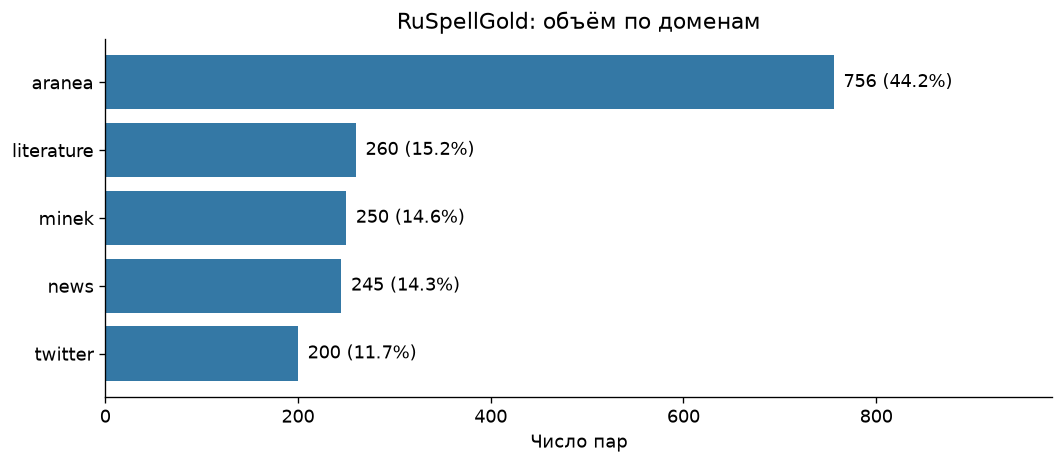

Крупнейший домен — aranea: 44.2% набора.


In [53]:
domain_counts = eda['domain'].value_counts()
domain_order = domain_counts.index.tolist()
counts = domain_counts.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(counts.index, counts.values, color=COLORS['source'])
for y, count in enumerate(counts):
    ax.text(count + 10, y, f'{count} ({count / len(eda):.1%})', va='center')
ax.set(xlabel='Число пар', title='RuSpellGold: объём по доменам', xlim=(0, counts.max() * 1.3))
fig.tight_layout()
fig.savefig(FIGURES / 'domains.png', bbox_inches='tight')
plt.show()
print(f'Крупнейший домен — {domain_order[0]}: {domain_counts.iloc[0] / len(eda):.1%} набора.')


## Длины текстов

Символы включают пробелы и пунктуацию; слова считаем по пробелам.


In [54]:
for column in ['source', 'correction']:
    eda[f'{column}_chars'] = eda[column].str.len()
    eda[f'{column}_words'] = eda[column].str.split().str.len()

length_columns = ['source_chars', 'correction_chars', 'source_words', 'correction_words']
length_summary = eda[length_columns].describe(percentiles=[0.5, 0.95]).T
length_summary = length_summary[['min', '50%', 'mean', '95%', 'max']]
length_summary.index = ['Исходник: символы', 'Исправление: символы',
                        'Исходник: слова', 'Исправление: слова']
display(length_summary.rename(columns={
    'min': 'Минимум', '50%': 'Медиана', 'mean': 'Среднее',
    '95%': '95-й процентиль', 'max': 'Максимум'}).round(1))


,Минимум,Медиана,Среднее,95-й процентиль,Максимум
Исходник: символы,17.0,151.0,172.8,372.0,628.0
Исправление: символы,17.0,151.0,172.9,371.5,629.0
Исходник: слова,2.0,21.0,24.2,52.0,116.0
Исправление: слова,2.0,21.0,24.2,52.0,114.0


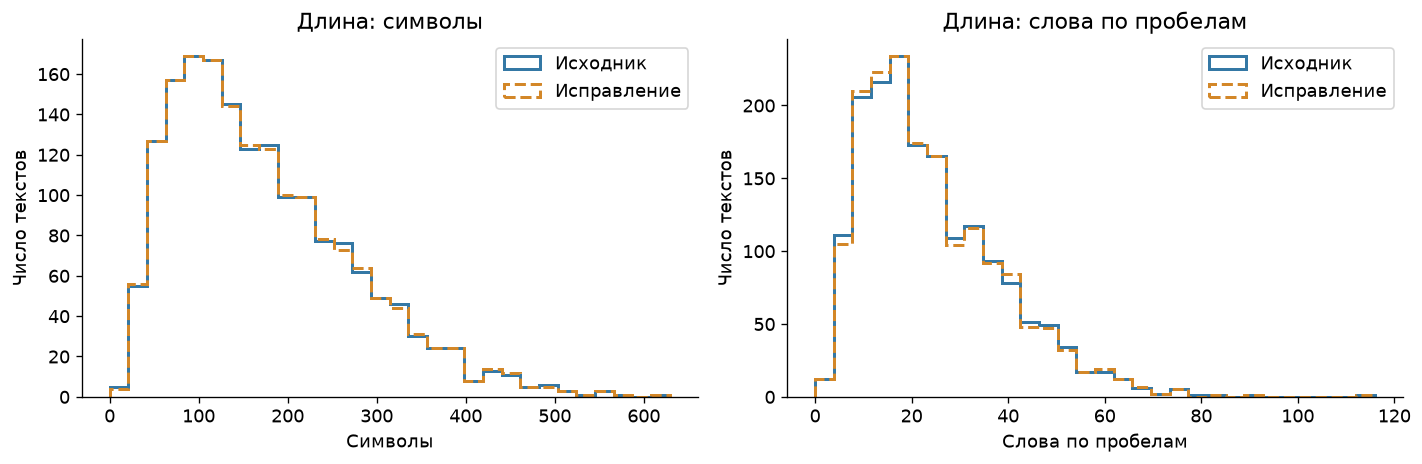

Медиана исходника: 151 символ, 21 слово по пробелам.


In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, suffix, label in zip(axes, ['chars', 'words'], ['Символы', 'Слова по пробелам']):
    maximum = eda[[f'source_{suffix}', f'correction_{suffix}']].to_numpy().max()
    bins = np.linspace(0, maximum, 31)
    for column, name in [('source', 'Исходник'), ('correction', 'Исправление')]:
        ax.hist(eda[f'{column}_{suffix}'], bins=bins, histtype='step', linewidth=1.8,
                label=name, color=COLORS[column], linestyle='-' if column == 'source' else '--')
    ax.set(xlabel=label, ylabel='Число текстов', title=f'Длина: {label.lower()}')
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'lengths.png', bbox_inches='tight')
plt.show()
print('Медиана исходника:', int(eda['source_chars'].median()), 'символ,',
      int(eda['source_words'].median()), 'слово по пробелам.')


## Длины по доменам

Точки — длинные значения; их не удаляем.


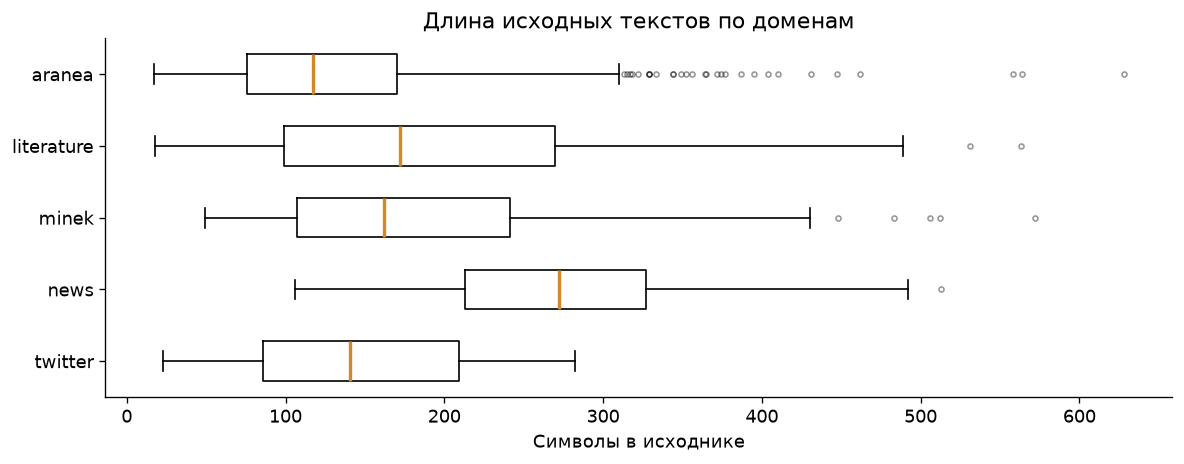

,"Медиана, символы","Максимум, символы"
domain,,
aranea,117.0,628
literature,172.0,563
minek,162.0,572
news,272.0,513
twitter,140.5,282


In [56]:
fig, ax = plt.subplots(figsize=(10, 4))
values = [eda.loc[eda['domain'].eq(domain), 'source_chars'] for domain in domain_order]
ax.boxplot(values, orientation='horizontal', widths=0.55,
           medianprops={'color': COLORS['correction'], 'linewidth': 2},
           flierprops={'markersize': 3, 'alpha': 0.4})
ax.set_yticks(range(1, len(domain_order) + 1), labels=domain_order)
ax.set(xlabel='Символы в исходнике', title='Длина исходных текстов по доменам')
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIGURES / 'domain_lengths.png', bbox_inches='tight')
plt.show()
display(eda.groupby('domain')['source_chars'].agg(['median', 'max']).loc[domain_order]
        .rename(columns={'median': 'Медиана, символы', 'max': 'Максимум, символы'}))


## Состав текста

Латиница, цифры и ссылки сами по себе не ошибки.


In [65]:
patterns = {'Кириллица': r'[А-Яа-яЁё]', 'Латиница': r'[A-Za-z]',
            'Цифры': r'\d',}
features = pd.DataFrame({
    'В скольки исходных': {name: int(eda['source'].str.contains(pattern, regex=True).sum())
                         for name, pattern in patterns.items()},
    'В скольки исправленных': {name: int(eda['correction'].str.contains(pattern, regex=True).sum())
                            for name, pattern in patterns.items()},
})
features['Исходник, %'] = (features['В скольки исходных'] / len(eda) * 100).round(1)
display(features)


,В скольки исходных,В скольки исправленных,"Исходник, %"
Кириллица,1711,1711,100.0
Латиница,199,198,11.6
Цифры,371,371,21.7


## Что меняется в парах

Автоматические взаимоисключающие группы. Пунктуация включает дефисы.


Без изменений: 491 (28.7%).
С изменениями: 1220 (71.3%).


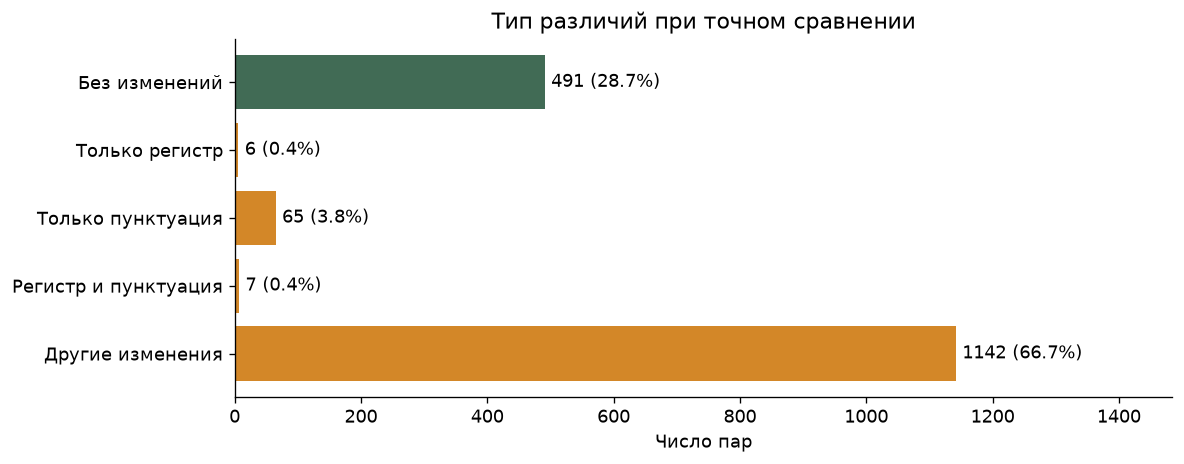

In [58]:
def remove_punctuation(text):
    return ''.join(char for char in text if not unicodedata.category(char).startswith('P'))

def change_group(source, correction):
    if source == correction:
        return 'Без изменений'
    if source.casefold() == correction.casefold():
        return 'Только регистр'
    if remove_punctuation(source) == remove_punctuation(correction):
        return 'Только пунктуация'
    if remove_punctuation(source.casefold()) == remove_punctuation(correction.casefold()):
        return 'Регистр и пунктуация'
    return 'Другие изменения'

group_order = ['Без изменений', 'Только регистр', 'Только пунктуация',
               'Регистр и пунктуация', 'Другие изменения']
eda['change_group'] = [change_group(a, b) for a, b in zip(eda['source_cmp'], eda['correction_cmp'])]
group_counts = eda['change_group'].value_counts().reindex(group_order, fill_value=0)
changed_count = int(eda['changed'].sum())
print(f'Без изменений: {len(eda) - changed_count} ({1 - eda["changed"].mean():.1%}).')
print(f'С изменениями: {changed_count} ({eda["changed"].mean():.1%}).')

counts = group_counts.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(counts.index, counts.values, color=[
    COLORS['unchanged'] if name == 'Без изменений' else COLORS['correction'] for name in counts.index])
for y, count in enumerate(counts):
    ax.text(count + 10, y, f'{count} ({count / len(eda):.1%})', va='center')
ax.set(xlabel='Число пар', title='Тип различий при точном сравнении', xlim=(0, counts.max() * 1.3))
fig.tight_layout()
fig.savefig(FIGURES / 'change_groups.png', bbox_inches='tight')
plt.show()


## Изменения по доменам

Доли — внутри каждого домена.


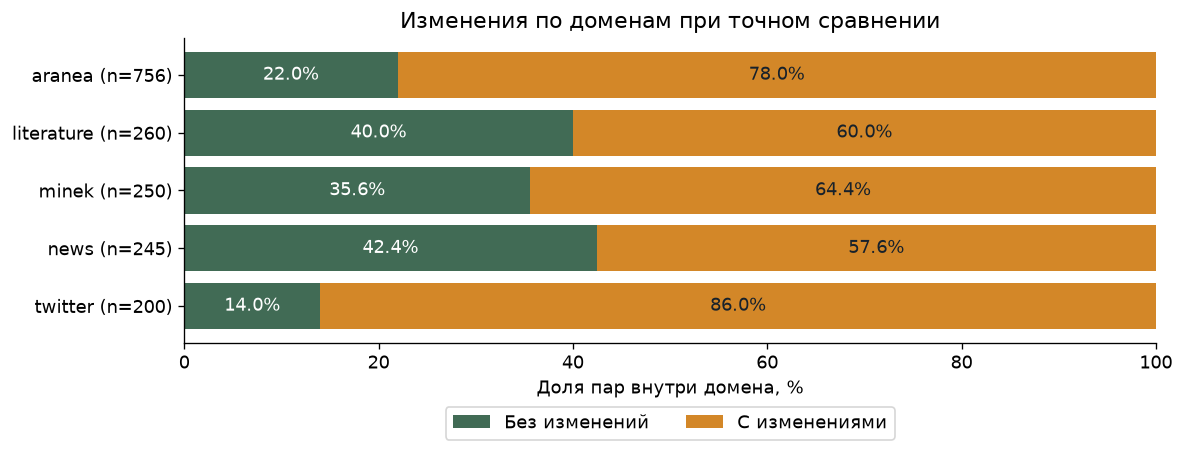

In [59]:
domain_changes = eda.groupby('domain')['changed'].agg(total='size', changed='sum').loc[domain_order]
domain_changes['unchanged'] = domain_changes['total'] - domain_changes['changed']
domain_changes['changed_pct'] = domain_changes['changed'] / domain_changes['total'] * 100
fig, ax = plt.subplots(figsize=(10, 4))
unchanged_pct = 100 - domain_changes['changed_pct']
ax.barh(domain_order, unchanged_pct, color=COLORS['unchanged'], label='Без изменений')
ax.barh(domain_order, domain_changes['changed_pct'], left=unchanged_pct,
        color=COLORS['correction'], label='С изменениями')
for y, (domain, row) in enumerate(domain_changes.iterrows()):
    ax.text(unchanged_pct.iloc[y] / 2, y, f'{unchanged_pct.iloc[y]:.1f}%', ha='center', va='center', color='white')
    ax.text(unchanged_pct.iloc[y] + row['changed_pct'] / 2, y, f'{row["changed_pct"]:.1f}%',
            ha='center', va='center', color='#17212b')
ax.set_yticks(range(len(domain_order)), labels=[
    f'{domain} (n={int(domain_changes.loc[domain, "total"])})' for domain in domain_order])
ax.set(xlim=(0, 100), xlabel='Доля пар внутри домена, %', title='Изменения по доменам при точном сравнении')
ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / 'domain_changes.png', bbox_inches='tight')
plt.show()


## Размер изменений

Левенштейн: минимум вставок, удалений и замен. Перестановка может дать две операции.


,Значение
Изменённых пар,1220.00
Медиана числа операций,2.00
95-й процентиль числа операций,6.00
Максимум операций,24.00
"Медиана операций / максимальная длина пары, %",1.11


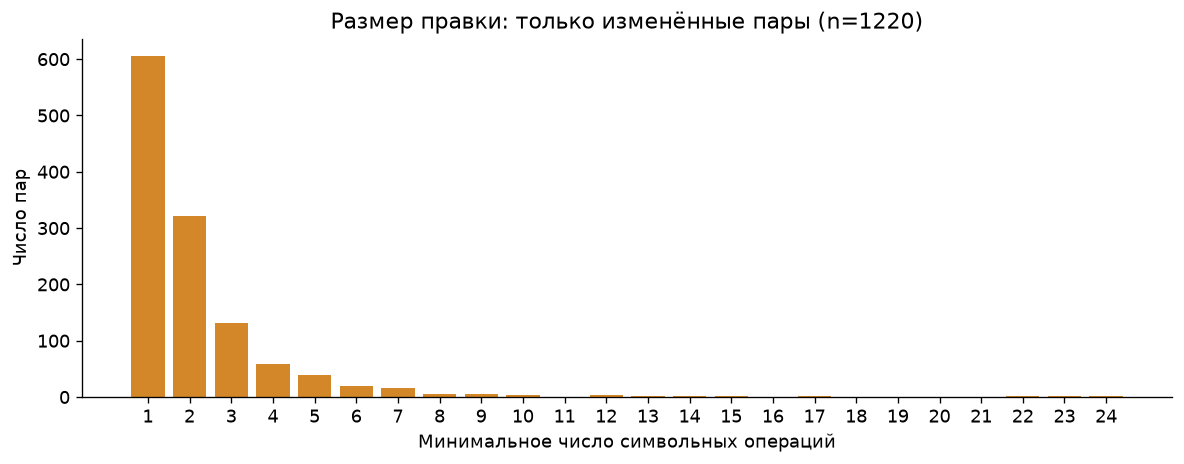

Одна операция: 606 пар (49.7% изменённых пар).


In [60]:
eda['edit_distance'] = [Levenshtein.distance(a, b) for a, b in zip(eda['source_cmp'], eda['correction_cmp'])]
changed = eda.loc[eda['changed']].copy()
changed['edit_share'] = changed['edit_distance'] / np.maximum(
    changed['source_cmp'].str.len(), changed['correction_cmp'].str.len()).clip(lower=1)
display(pd.Series({
    'Изменённых пар': len(changed),
    'Медиана числа операций': changed['edit_distance'].median(),
    '95-й процентиль числа операций': changed['edit_distance'].quantile(0.95),
    'Максимум операций': changed['edit_distance'].max(),
    'Медиана операций / максимальная длина пары, %': changed['edit_share'].median() * 100,
}, name='Значение').round(2).to_frame())

frequencies = changed['edit_distance'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(frequencies.index, frequencies.values, color=COLORS['correction'])
ax.set(xlabel='Минимальное число символьных операций', ylabel='Число пар',
       title=f'Размер правки: только изменённые пары (n={len(changed)})')
ax.set_xticks(range(1, int(frequencies.index.max()) + 1))
fig.tight_layout()
fig.savefig(FIGURES / 'edit_distances.png', bbox_inches='tight')
plt.show()
print(f'Одна операция: {(changed["edit_distance"] == 1).sum()} пар '
      f'({changed["edit_distance"].eq(1).mean():.1%} изменённых пар).')


## Символьные операции

Одно минимальное выравнивание. Операции не равны числу языковых ошибок.


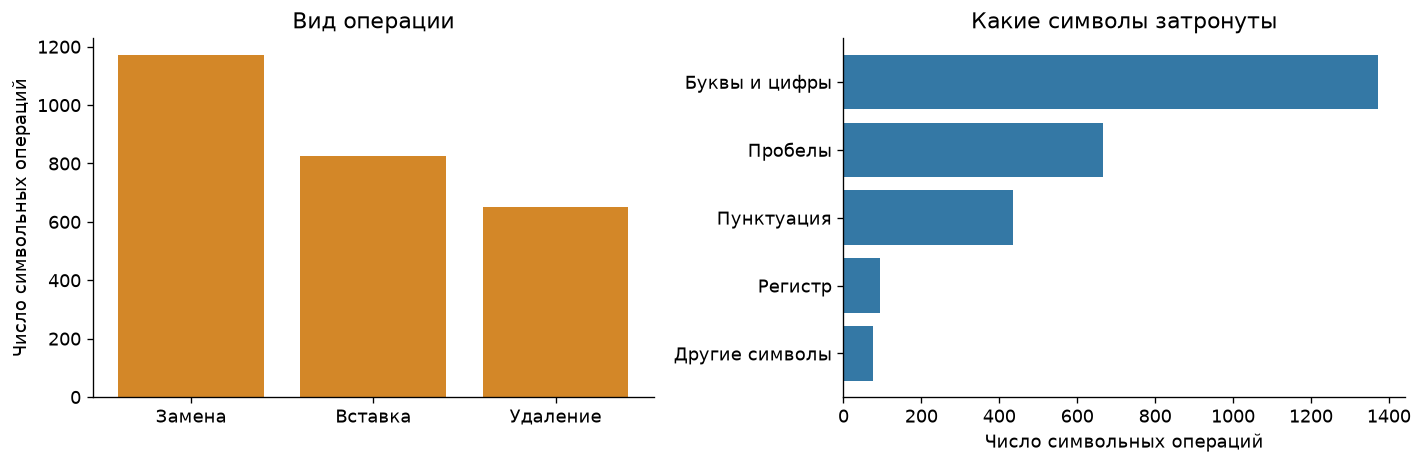

,Количество
Удаления,649
Замены,1170
Вставки,826


In [61]:
operations = Counter()
operation_chars = Counter()
for source, correction in zip(eda['source_cmp'], eda['correction_cmp']):
    for tag, source_pos, correction_pos in Levenshtein.editops(source, correction):
        operations[tag] += 1
        before = source[source_pos] if tag != 'insert' else ''
        after = correction[correction_pos] if tag != 'delete' else ''
        if tag == 'replace' and before.casefold() == after.casefold():
            category = 'Регистр'
        elif (before + after).isspace():
            category = 'Пробелы'
        elif all(unicodedata.category(char).startswith('P') for char in before + after):
            category = 'Пунктуация'
        elif any(char.isalnum() for char in before + after):
            category = 'Буквы и цифры'
        else:
            category = 'Другие символы'
        operation_chars[category] += 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
values = pd.Series(operations).reindex(['replace', 'insert', 'delete'], fill_value=0)
axes[0].bar(['Замена', 'Вставка', 'Удаление'], values.values, color=COLORS['correction'])
axes[0].set(title='Вид операции', ylabel='Число символьных операций')
values = pd.Series(operation_chars).sort_values()
axes[1].barh(values.index, values.values, color=COLORS['source'])
axes[1].set(title='Какие символы затронуты', xlabel='Число символьных операций')
fig.tight_layout()
fig.savefig(FIGURES / 'edit_operations.png', bbox_inches='tight')
plt.show()
display(pd.Series(operations).rename(index={'replace': 'Замены', 'insert': 'Вставки', 'delete': 'Удаления'})
        .rename('Количество').to_frame())


## Примеры пар

Оригинал - готовое исправление из RuSpellGold.


In [62]:
examples = []
for group in group_order:
    candidates = eda.loc[eda['change_group'].eq(group) & eda['source_chars'].le(90)
                         & eda['correction_chars'].le(90)]
    examples.append(candidates.head(1))
example_pairs = pd.concat(examples)[['domain', 'change_group', 'source', 'correction', 'edit_distance']]
display(example_pairs.rename(columns={'domain': 'Домен', 'change_group': 'Группа',
                                     'source': 'Исходник', 'correction': 'Исправление',
                                     'edit_distance': 'Операции'}).reset_index(drop=True))


,Домен,Группа,Исходник,Исправление,Операции
0,aranea,Без изменений,(Серым пофиг - только за 6 месяцами проследите),(Серым пофиг - только за 6 месяцами проследите),0
1,aranea,Только регистр,"Cинтаксис и пунктуация рядышком идут, Держатся за руки, песенки поют.","Cинтаксис и пунктуация рядышком идут, держатся за руки, песенки поют.",1
2,aranea,Только пунктуация,"Вконтакте можно создать свою группу по теме своего СДЛ, и звать туда людей.",Вконтакте можно создать свою группу по теме своего СДЛ и звать туда людей.,1
3,aranea,Регистр и пунктуация,КТО стоял за колониальной политикой Династии Романовых и брато-убийственными войнами???,Кто стоял за колониальной политикой Династии Романовых и братоубийственными войнами???,3
4,aranea,Другие изменения,"Видела в городе афиши, анонсрующие ее концерт.","Видела в городе афиши, анонсирующие её концерт",3


## Выводы

Изменения есть в 71,3% пар; 28,7% совпадают полностью.

Большинство правок небольшие: 76% изменённых пар требуют 1–2 операции (49,7% — одну, 26,3% — две).

У 96,4% изменённых пар не более шести операций; максимум — 24.
